In [1]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DB = next(p for p in [Path("../data/carepulse.db"), Path("data/carepulse.db")] if p.exists())
con = sqlite3.connect(DB)
df = pd.read_sql("SELECT * FROM mart_fct_index_discharges", con)

In [2]:
print(df.shape)

(7937, 20)


In [5]:
def rate_with_ci(frame, col):
    g = frame.groupby(col)["is_readmission_30d"].agg(["count", "sum"])
    g["rate"] = g["sum"] / g["count"]
    se = np.sqrt(g["rate"] * (1 - g["rate"]) / g["count"])
    g["low"] = ((g["rate"] - 1.96 * se) * 100).clip(lower=0)
    g["high"] = (g["rate"] + 1.96 * se) * 100
    g["rate"] *= 100
    return g.round(2)

## 1. Department

In [11]:
g = rate_with_ci(df, "department").sort_values("rate", ascending=False)
g

,count,sum,rate,low,high
department,,,,,
Pulmonology,851,151,17.74,15.18,20.31
Nephrology,566,97,17.14,14.03,20.24
Cardiology,1032,155,15.02,12.84,17.20
Oncology,705,102,14.47,11.87,17.06
Neurology,583,82,14.07,11.24,16.89
Emergency,810,112,13.83,11.45,16.20
General Medicine,1717,220,12.81,11.23,14.39
Orthopedics,925,114,12.32,10.21,14.44
Gastroenterology,748,82,10.96,8.72,13.20


### Department-Wise Readmission Rate & 95% CI Insights
* **Highest-Risk Departments:** **Pulmonology** (**17.74%**, 95% CI: 15.18%–20.31%) and **Nephrology** (**17.14%**, 95% CI: 14.03%–20.24%) record the highest 30-day readmission rates among the displayed departments, followed by **Cardiology** (**15.02%**) and **Oncology** (**14.47%**).
* **Volume vs. Rate Distinction:** **General Medicine** handles the highest volume (1,717 encounters, 220 readmissions) but has a comparatively lower readmission rate (**12.81%**, 95% CI: 11.23%–14.39%), showing that high case volume does not automatically imply the highest readmission rate.
* **Precision & Uncertainty:** Smaller cohorts like **Nephrology** (n = 566) and **Neurology** (n = 583) exhibit wider 95% confidence intervals than larger cohorts like **General Medicine** (n = 1,717), making formal hypothesis testing (such as a chi-square test across departments) useful to confirm statistically significant differences.

## 2.Department Readmission Rates

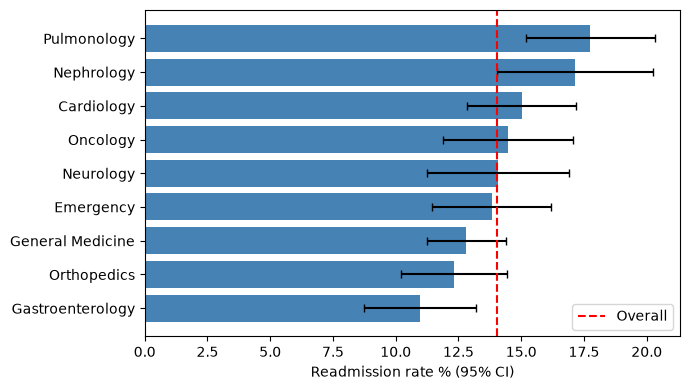

In [7]:
g = g.sort_values("rate")
plt.figure(figsize=(7, 4))
plt.barh(g.index, g["rate"], xerr=[g["rate"] - g["low"], g["high"] - g["rate"]],
         color="steelblue", capsize=3)
plt.axvline(df["is_readmission_30d"].mean() * 100, color="red", ls="--", label="Overall")
plt.xlabel("Readmission rate % (95% CI)")
plt.legend() plt.tight_layout(); plt.show()

### Department Readmission Rates with 95% Confidence Intervals
* **Statistically Higher Than Overall Average:** Both **Pulmonology** (**17.74%**, 95% CI: 15.18%–20.31%) and **Nephrology** (**17.14%**, 95% CI: 14.03%–20.24%) have entire 95% confidence intervals positioned above the overall baseline (~14%), confirming significantly elevated readmission risk.
* **Statistically Lower Than Overall Average:** **Gastroenterology** is the only department whose entire 95% confidence interval falls cleanly below the overall average line, indicating a significantly lower readmission rate.
* **Consistent With Hospital Average:** The 95% confidence intervals for **Cardiology**, **Oncology**, **Neurology**, **Emergency**,**General Medicine**, and **Orthopedics** all overlap with the overall benchmark line, suggesting their differences from the hospital-wide average are within expected sampling variation.
* **Sample Size Precision:** **General Medicine** exhibits the tightest confidence interval due to its large sample size (n = 1,717), whereas smaller departments like **Nephrology** (n = 566) show wider uncertainty bounds.

## 3. Payer, Age band, Chronic conditions, Prior band

In [8]:
df["chronic_band"] = df["chronic_conditions"].clip(upper=3).map(lambda v: "3+" if v >= 3 else str(int(v)))
df["prior_band"] = df["prior_inpatient_admissions"].clip(upper=3).map(lambda v: "3+" if v >= 3 else str(int(v)))

for c in ["payer_type", "age_band", "chronic_band", "prior_band"]:
    print(f"--- {c} ---")
    print(rate_with_ci(df, c), "\n")

--- payer_type ---
            count  sum   rate    low   high
payer_type                                 
Government   2798  381  13.62  12.35  14.89
Private      3254  437  13.43  12.26  14.60
Self-pay     1817  288  15.85  14.17  17.53
Unknown        68    9  13.24   5.18  21.29 

--- age_band ---
          count  sum   rate    low   high
age_band                                 
0-17         29    3  10.34   0.00  21.43
18-29       615   56   9.11   6.83  11.38
30-44      1902  237  12.46  10.98  13.94
45-59      2712  374  13.79  12.49  15.09
60-74      1873  302  16.12  14.46  17.79
75+         806  143  17.74  15.10  20.38 

--- chronic_band ---
              count  sum   rate    low   high
chronic_band                                 
0               326   25   7.67   4.78  10.56
1               712   60   8.43   6.39  10.47
2               925  104  11.24   9.21  13.28
3+             5974  926  15.50  14.58  16.42 

--- prior_band ---
            count  sum   rate    low   hig

### Subgroup Readmission Rates & 95% CI Insights
* **Payer Type:** **Self-pay** patients exhibit the highest 30-day readmission rate at **15.85%** (95% CI: 14.17%–17.53%), noticeably higher than **Government** (**13.62%**) and **Private** (**13.43%**) payers. The Unknown group (`n = 68`) has too small a sample size for reliable inference (95% CI: 5.18%–21.29%).
* **Age Band:** Excluding the tiny 0-17 cohort (n = 29, 95% CI: `0.00%–21.43%`), readmission rates climb steadily from **9.11%** (18-29) to **17.74%** (75+). Non-overlapping confidence intervals between younger (18-44) and older (60+) groups confirm a statistically meaningful age effect.
* **Chronic Conditions:** Patients with **3+ chronic conditions** make up the largest cohort (n = 5,974) and face a **15.50%** readmission rate (95% CI: 14.58%–16.42%)—roughly double that of patients with 0 (**7.67%**) or `1` (**8.43%**) chronic condition.
* **Prior Inpatient Admissions:** Readmission risk escalates sharply across every tier—from **9.84%** (0 prior admissions) and **11.92%** (1) to 15.07% (2) and **20.06%** (3+, 95% CI: 18.39%–21.73%)—making prior admissions the strongest subgroup differentiator.

## 4.Two-Proportion Z-Test Results

In [10]:
from math import erf, sqrt

def two_prop_z(a, b):
    
    p1, p2 = a.mean(), b.mean()
    n1, n2 = len(a), len(b)
    p = (a.sum() + b.sum()) / (n1 + n2)
    z = (p1 - p2) / sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    pval = 2 * (1 - 0.5 * (1 + erf(abs(z) / sqrt(2))))
    return round(float((p1 - p2) * 100), 2), round(float(z), 2), float(pval)

old = df.loc[df["age_band"] == "75+", "is_readmission_30d"]
rest = df.loc[df["age_band"] != "75+", "is_readmission_30d"]
print("75+ Vs Rest:", two_prop_z(old, rest))

heavy = df.loc[df["prior_inpatient_admissions"] >= 3, "is_readmission_30d"]
light = df.loc[df["prior_inpatient_admissions"] < 3, "is_readmission_30d"]
print("3+ Old admissions Vs Rest:", two_prop_z(heavy, light))

pulm = df.loc[df["department"] == "Pulmonology", "is_readmission_30d"]
gastro = df.loc[df["department"] == "Gastroenterology", "is_readmission_30d"]
print("Pulmonology Vs Gastroenterology:", two_prop_z(pulm, gastro))

75+ Vs Rest: (4.11, 3.18, 0.0014531145531195833)
3+ Old admissions Vs Rest: (8.34, 9.59, 0.0)
Pulmonology Vs Gastroenterology: (6.78, 3.83, 0.0001256465076246993)


### Two-Proportion Z-Test Results (Hypothesis Testing)
All three subgroup comparisons show statistically significant differences in 30-day readmission rates ($\alpha = 0.05$):

* **75+ Age Group vs. All Other Ages:** Patients aged 75+ have a **+4.11 percentage point** higher readmission rate ($z = 3.18$, $p = 0.0015$), confirming that advanced age significantly increases readmission risk.
* **3+ Prior Inpatient Admissions vs. <3:** Patients with 3+ prior admissions exhibit an **+8.34 percentage point** higher readmission rate ($z = 9.59$, $p < 0.0001$), representing the strongest statistical effect among tested subgroups.
* **Pulmonology vs. Gastroenterology:** Pulmonology exceeds Gastroenterology by **+6.78 percentage points** ($z = 3.83$, $p = 0.0001$), validating a statistically significant gap between the highest- and lowest-risk departments.
* Conclusion: The observed patterns across age, prior hospitalization history, and clinical department are statistically robust rather than sampling noise, justifying their inclusion in risk stratification and predictive modeling.